In [1]:
# CIFAR-10
# MNIST

In [2]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import matplotlib.pyplot as plt

In [3]:
!pwd

/content


In [4]:
!mkdir data

In [5]:
transform = transforms.ToTensor()

train_ds = datasets.MNIST(root='./content/data', train=True, transform=transform, download=True)
test_ds = datasets.MNIST(root='./content/data', train=False, transform=transform, download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.9MB/s]


In [6]:
train_ds

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./content/data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [7]:
test_ds

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./content/data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [8]:
print(train_ds.data.shape)
print(test_ds.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


In [9]:
print(train_ds.classes)
print(train_ds.class_to_idx)

['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
{'0 - zero': 0, '1 - one': 1, '2 - two': 2, '3 - three': 3, '4 - four': 4, '5 - five': 5, '6 - six': 6, '7 - seven': 7, '8 - eight': 8, '9 - nine': 9}


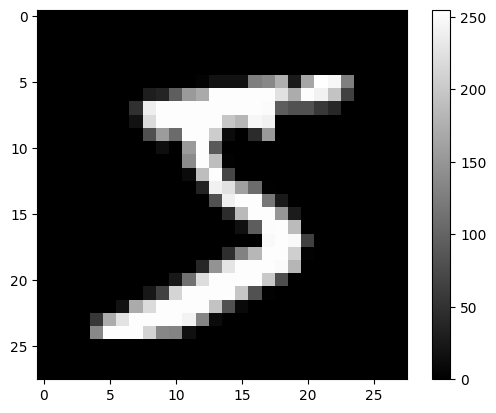

In [10]:
plt.imshow(train_ds.data[0], cmap='gray')
plt.colorbar()

In [11]:
train_ds.targets

tensor([5, 0, 4,  ..., 5, 6, 8])

In [12]:
# 하이퍼파라미터
epochs = 500
batch_size = 32
learning_rate = 0.01

In [13]:
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=True)

In [14]:
x_batch, y_batch = next(iter(train_dl))

In [15]:
print(x_batch.shape)
print(y_batch.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


In [16]:
# MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        # nn.Linear()의 입력은 개x채 또는 개x개x채
        self.fcs = nn.Sequential(nn.Linear(28*28, 100),
                                 nn.ReLU(),
                                 nn.Linear(100, 10))

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.fcs(x)
        return x

In [32]:
# CNN
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        # in_channels: input data의 채널수
        # out_channels: 필터 개수(=피처맵 채널수)
        # kernel_size: 이미지의 특징 패턴을 뽑아낼 필터의 영역 크기
        self.conv = nn.Sequential(nn.Conv2d(1, 3, 3),
                                  nn.ReLU(),
                                  nn.Conv2d(3, 3, 3),
                                  nn.ReLU())
        self.fc = nn.Linear(3*24*24, 10)

    def forward(self, x):
        x = self.conv(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [ ]:
class CNN_deep(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_block1 = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1),
                                         nn.ReLU(),
                                         nn.Conv2d(32, 32, 3, padding=1),
                                         nn.ReLU())
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv_block2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1),
                                         nn.ReLU(),
                                         nn.Conv2d(64, 64, 3, padding=1),
                                         nn.ReLU())
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv_block3 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1),
                                         nn.ReLU(),
                                         nn.Conv2d(128, 128, 3, padding=1),
                                         nn.ReLU())
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(128*3*3, 10)

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.maxpool1(x)
        x = self.conv_block2(x)
        x = self.maxpool2(x)
        x = self.conv_block3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [18]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


DNN

In [19]:
model = MLP()
model.to(device)
criterion = nn.CrossEntropyLoss() # softmax 포함
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [35]:
def train(num_epochs, data, model, criterion, optimizer):
    losses = []
    for epoch in range(num_epochs):
        running_loss = 0
        for x, y in data:
            x = x.to(device)
            y = y.to(device)
            # inference
            y_hat = model(x)
            # loss
            loss = criterion(y_hat, y)

            # gradient 초기화(누적 방지)
            optimizer.zero_grad()
            # 미분
            loss.backward()
            # 업데이트
            optimizer.step()

            # nn.CrossEntropyLoss() 평균을 구함
            loss_b = loss.item() * x.shape[0]
            running_loss += loss_b
        loss_e = running_loss / len(data.dataset)
        losses.append(loss_e)
        if epoch % 20 == 0:
            print(f'epoch:{epoch}, loss: {loss_e:.3f}')

    print('----'*15)
    print(f'epoch:{epoch}, loss: {loss_e:.3f}')

    return losses

In [38]:
def plot_loss(losses):
    plt.plot(losses)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()

In [36]:
def test(model, data):
    model.eval()
    with torch.no_grad():
        corrects = 0
        for x, y in data:
            x = x.to(device)
            y = y.to(device)

            y_hat = model(x)
            pred = y_hat.argmax(dim=1)
            correct_b = (y == pred).sum().item()
            corrects += correct_b
        accuracy = corrects / len(data.dataset) * 100
        print(f'Accuracy: {accuracy:.2f}')

CNN

In [33]:
model_cnn = CNN()
model_cnn.to(device)

CNN(
  (conv): Sequential(
    (0): Conv2d(1, 3, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
  )
  (fc): Linear(in_features=1728, out_features=10, bias=True)
)

In [34]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_cnn.parameters(), lr=learning_rate)

In [37]:
losses = train(200, train_dl, model_cnn, criterion, optimizer)

epoch:0, loss: 2.302
epoch:20, loss: 0.054
epoch:40, loss: 0.036
epoch:60, loss: 0.026
epoch:80, loss: 0.017
epoch:100, loss: 0.012
epoch:120, loss: 0.007
epoch:140, loss: 0.003
epoch:160, loss: 0.001
epoch:180, loss: 0.000
------------------------------------------------------------
epoch:199, loss: 0.000


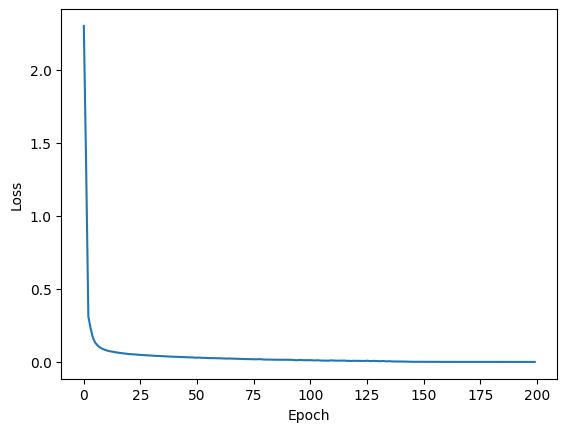

In [39]:
plot_loss(losses)

In [40]:
test(model_cnn, test_dl)

Accuracy: 97.24


In [41]:
!mkdir model

In [44]:
# 모델 저장
model_path = '/content/model/CNN.pt'
torch.save(model_cnn.state_dict(), model_path)

In [45]:
# 모델 불러오기
load_model = CNN().to(device)
load_model.load_state_dict(torch.load(model_path, map_location=device))

<All keys matched successfully>